# Le futur de l'Italie. Les pépites de la Primavera 1, saison 2025/26

**Objectif** : identifier, poste par poste, les meilleurs jeunes joueurs italiens (nés entre 2006 et 2009) de la Primavera 1 2025/26, uniquement à partir de leurs statistiques.

**Source des données** : SofaScore.

**Périmètre** : joueurs italiens nés entre 2006 et 2009 ayant joué au moins 810 minutes (9 matchs complets). Les moyennes de comparaison sont calculées sur deux groupes : les jeunes Italiens retenus, et l'ensemble des joueurs de Primavera 1 ayant joué au moins 810 minutes.

**Plan** : 1. Connexion à SofaScore. 2. Récupération des joueurs. 3. Calcul des indicateurs. 4. Méthode de classement et radars. 5. Gardiens. 6. Défenseurs. 7. Milieux. 8. Attaquants. 9. XI type des pépites. 10. Limites de la méthode.

## 1. Connexion à SofaScore

SofaScore bloque les programmes qui ne ressemblent pas à un vrai navigateur. On utilise donc la librairie curl_cffi, qui imite Chrome. Une pause d'une seconde entre chaque demande évite d'être bloqué, et en cas de refus le programme attend 30 secondes avant de réessayer.

La première cellule installe curl_cffi (sans effet s'il est déjà installé). Ensuite, le notebook teste plusieurs empreintes de navigateur (Chrome, Safari, Edge, Firefox) et garde la première que SofaScore accepte. Si SofaScore se met à refuser toutes les demandes pendant le téléchargement, le programme s'arrête au lieu de tourner dans le vide, et ce qui a déjà été téléchargé est conservé.

In [1]:
# On installe la librairie curl_cffi (si elle est déjà installée, cette ligne ne change rien)
%pip install curl_cffi --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# On importe la partie "requests" de curl_cffi, qui imite le navigateur Chrome (SofaScore bloque les robots classiques)
from curl_cffi import requests as creq
# On importe time pour faire des pauses entre les demandes
import time
# On importe os pour vérifier si un fichier existe déjà sur l'ordinateur
import os
# On importe pandas pour manipuler les tableaux de données
import pandas as pd
# On importe numpy pour les calculs des radars (angles, valeurs)
import numpy as np
# On importe matplotlib pour dessiner les radars et le terrain du XI type
import matplotlib.pyplot as plt

# Identifiant SofaScore de la Primavera 1
ID_TOURNOI = 2292
# Identifiant SofaScore de la saison 2025/26 de la Primavera 1
ID_SAISON = 77407
# Temps de jeu minimum pour être pris en compte : 810 minutes, soit 9 matchs complets
SEUIL_MINUTES = 810
# Temps de jeu maximum possible sur la saison : 38 journées x 90 minutes (sert d'information)
MINUTES_SAISON = 38 * 90

# Pause (en secondes) après chaque demande : plus elle est longue, moins SofaScore nous repère, mais plus c'est long
PAUSE = 5
# Navigateur imité par défaut (il sera remplacé par celui que SofaScore accepte, voir plus bas)
NAVIGATEUR = "chrome"
# Compteur de demandes refusées d'affilée, pour détecter un blocage complet
ECHECS_DAFFILEE = 0
# Nombre de refus d'affilée à partir duquel on considère que SofaScore nous bloque complètement
ECHECS_MAX = 5

# Fonction qui interroge SofaScore et renvoie les données, avec plusieurs essais en cas de blocage
def get_sofascore(url, essais=3):
    # On indique qu'on va modifier le compteur de refus défini en dehors de la fonction
    global ECHECS_DAFFILEE
    # On fait au maximum "essais" tentatives
    for tentative in range(essais):
        # On envoie la demande en imitant le navigateur choisi, avec le site SofaScore comme provenance
        reponse = creq.get(url, impersonate=NAVIGATEUR, headers={"Referer": "https://www.sofascore.com/"})
        # Pause après chaque demande (valeur PAUSE) pour ne pas être repéré comme un robot
        time.sleep(PAUSE)
        # Code 200 = tout va bien
        if reponse.status_code == 200:
            # La demande a marché : on remet le compteur de refus à zéro
            ECHECS_DAFFILEE = 0
            # On renvoie les données lisibles
            return reponse.json()
        # Code 404 = la page n'existe pas (par exemple un joueur sans stats), inutile de réessayer
        if reponse.status_code == 404:
            return None
        # Autre code (souvent 403 ou 429 = blocage) : on prévient et on attend avant de réessayer
        print("Code", reponse.status_code, ": nouvelle tentative dans 30 secondes")
        # On attend 30 secondes pour laisser SofaScore se calmer
        time.sleep(30)
    # Toutes les tentatives ont échoué : on augmente le compteur de refus d'affilée
    ECHECS_DAFFILEE += 1
    # Si trop de demandes ont été refusées d'affilée, SofaScore nous bloque : on arrête tout
    if ECHECS_DAFFILEE >= ECHECS_MAX:
        raise RuntimeError("SofaScore refuse toutes les demandes (blocage). Ce qui a déjà été téléchargé est "
                           "sauvegardé. Réessaie plus tard, après avoir redémarré ta box internet, "
                           "ou via le partage de connexion de ton téléphone.")
    # Sinon on renvoie None (rien) et on passe à la suite
    return None

# Liste des empreintes de navigateur à tester, de la plus courante à la moins courante
NAVIGATEURS_A_TESTER = ["chrome", "chrome131", "chrome124", "safari", "safari17_0", "edge101", "firefox133"]
# Adresse simple qui sert uniquement à tester l'accès à SofaScore
URL_TEST = f"https://www.sofascore.com/api/v1/unique-tournament/{ID_TOURNOI}/seasons"

# On teste chaque empreinte une par une
for nav in NAVIGATEURS_A_TESTER:
    # On essaie la demande de test avec cette empreinte
    try:
        # On envoie la demande en imitant ce navigateur
        code = creq.get(URL_TEST, impersonate=nav, headers={"Referer": "https://www.sofascore.com/"}).status_code
    # Si cette empreinte n'existe pas dans la version installée de curl_cffi, on passe à la suivante
    except Exception:
        continue
    # On affiche le résultat du test
    print("Test", nav, ": code", code)
    # Petite pause entre deux tests
    time.sleep(1.5)
    # Si SofaScore accepte cette empreinte, on la garde et on arrête les tests
    if code == 200:
        NAVIGATEUR = nav
        break
# Si aucune empreinte n'a été acceptée, on prévient clairement
else:
    print("Aucun navigateur accepté : c'est ton adresse internet qui est bloquée. Redémarre ta box internet "
          "ou utilise le partage de connexion de ton téléphone, puis relance cette cellule.")
# On affiche le navigateur retenu
print("Navigateur utilisé :", NAVIGATEUR)

Test chrome : code 200
Navigateur utilisé : chrome


## 2. Récupération des joueurs de la Primavera 1

Pour chaque poste (gardien, défenseur, milieu, attaquant), on récupère la liste des joueurs, puis pour chacun sa nationalité, son année de naissance et toutes ses statistiques de la saison. On garde tous les joueurs, et pas seulement les jeunes Italiens, pour pouvoir calculer la moyenne de toute la Primavera.

Chaque poste est sauvegardé dans son propre fichier dès qu'il est terminé, puis les 4 postes sont rassemblés dans `primavera_2526_complet.csv`. Si un fichier existe déjà, il est simplement rechargé : en cas de blocage en cours de route, il suffit de relancer plus tard et le téléchargement reprend au poste où il s'était arrêté. Avec une pause de 5 secondes entre chaque demande, le téléchargement complet prend environ 2 heures, mais il ne se fait qu'une seule fois.

In [3]:
# Correspondance entre le code de poste SofaScore et le nom du poste en français
POSTES = {"G": "Gardien", "D": "Défenseur", "M": "Milieu", "F": "Attaquant"}

# Fonction qui renvoie la liste des joueurs (identifiant, nom, équipe) d'un poste en Primavera 1
def lister_joueurs(code_poste):
    # Liste vide qui recevra les joueurs
    joueurs = []
    # On commence à la première page de résultats
    offset = 0
    # On boucle tant qu'il reste des pages
    while True:
        # Adresse de la liste des joueurs du poste demandé, 100 par page
        url = (f"https://www.sofascore.com/api/v1/unique-tournament/{ID_TOURNOI}/season/{ID_SAISON}/statistics"
               f"?limit=100&offset={offset}&order=-rating&accumulation=total&group=summary"
               f"&filters=position.in.{code_poste}")
        # On envoie la demande
        donnees = get_sofascore(url)
        # Si la demande échoue ou si la page est vide, on a fini
        if donnees is None or not donnees.get("results"):
            break
        # On parcourt chaque joueur de la page
        for ligne in donnees["results"]:
            # On garde son identifiant, son nom et son équipe
            joueurs.append({"id_joueur": ligne["player"]["id"], "nom": ligne["player"]["name"],
                            "equipe": ligne["team"]["name"]})
        # Si on est sur la dernière page, on arrête
        if donnees.get("page", 1) >= donnees.get("pages", 1):
            break
        # Sinon on passe aux 100 joueurs suivants
        offset += 100
    # On renvoie la liste complète
    return joueurs

# Fonction qui récupère tous les joueurs d'un poste avec leurs infos et leurs stats, ou recharge son fichier s'il existe
def recuperer_poste(code_poste, nom_poste):
    # Nom du fichier de sauvegarde du poste (par exemple primavera_2526_poste_G.csv)
    fichier = f"primavera_2526_poste_{code_poste}.csv"
    # Si ce poste a déjà été téléchargé et que son fichier n'est pas vide, on le recharge sans rien télécharger
    if os.path.exists(fichier) and os.path.getsize(fichier) > 10:
        # Message pour savoir que ce poste vient du fichier
        print(nom_poste, ": fichier déjà présent, chargement sans nouveau téléchargement")
        # On renvoie le tableau lu depuis le fichier
        return pd.read_csv(fichier)
    # Si un fichier vide traîne (téléchargement raté), on le supprime pour repartir proprement
    if os.path.exists(fichier):
        os.remove(fichier)
    # On récupère la liste des joueurs du poste
    joueurs = lister_joueurs(code_poste)
    # Si la liste est vide, c'est que SofaScore a refusé la demande : on arrête sans rien sauvegarder
    if len(joueurs) == 0:
        raise RuntimeError(f"Aucun joueur trouvé au poste {nom_poste} : SofaScore bloque probablement les demandes. "
                           "Rien n'a été sauvegardé pour ce poste, réessaie plus tard.")
    # On affiche combien de joueurs ont été trouvés à ce poste
    print(nom_poste, ":", len(joueurs), "joueurs trouvés")
    # Liste vide qui recevra une ligne par joueur
    lignes = []
    # On parcourt chaque joueur, en le numérotant pour suivre l'avancement
    for i, joueur in enumerate(joueurs, start=1):
        # On récupère sa fiche personnelle (nationalité, date de naissance)
        fiche = get_sofascore(f"https://www.sofascore.com/api/v1/player/{joueur['id_joueur']}")
        # Si la fiche est introuvable, on passe au suivant
        if fiche is None:
            continue
        # On récupère la partie "player" de la fiche
        infos = fiche.get("player", {})
        # On récupère le pays du joueur (par exemple "Italy")
        pays = infos.get("country", {}).get("name")
        # On récupère sa date de naissance, donnée en secondes depuis 1970
        timestamp = infos.get("dateOfBirthTimestamp")
        # On la convertit en année, ou vide si elle n'existe pas
        annee = pd.to_datetime(timestamp, unit="s").year if timestamp is not None else None
        # Adresse de ses stats de la saison 2025/26 en Primavera 1
        url_stats = (f"https://www.sofascore.com/api/v1/player/{joueur['id_joueur']}/unique-tournament/"
                     f"{ID_TOURNOI}/season/{ID_SAISON}/statistics/overall")
        # On récupère ses stats
        stats = get_sofascore(url_stats)
        # Si la demande échoue, on passe au suivant
        if stats is None:
            continue
        # On crée sa ligne avec ses infos de base
        ligne = {"id_joueur": joueur["id_joueur"], "nom": joueur["nom"], "equipe": joueur["equipe"],
                 "poste": nom_poste, "nationalite": pays, "annee_naissance": annee}
        # On ajoute toutes ses stats d'un coup
        ligne.update(stats.get("statistics", {}))
        # On ajoute la ligne à la liste
        lignes.append(ligne)
        # Tous les 50 joueurs, on affiche l'avancement pour savoir où on en est
        if i % 50 == 0:
            print("   ", i, "/", len(joueurs), "joueurs traités")
    # Si aucun joueur n'a pu être récupéré, on arrête sans sauvegarder de fichier vide
    if len(lignes) == 0:
        raise RuntimeError(f"Aucune statistique récupérée au poste {nom_poste} : rien n'a été sauvegardé.")
    # On transforme la liste en tableau
    df = pd.DataFrame(lignes)
    # On sauvegarde le poste dans son fichier : s'il y a un blocage plus tard, ce poste n'est pas à refaire
    df.to_csv(fichier, index=False)
    # On renvoie le tableau du poste
    return df

# Fonction qui rassemble les 4 postes dans un seul tableau, ou recharge le fichier complet s'il existe
def recuperer_primavera(fichier="primavera_2526_complet.csv"):
    # Si le fichier complet existe déjà, on le recharge directement
    if os.path.exists(fichier):
        # Message pour savoir que les données viennent du fichier
        print("Fichier complet déjà présent : chargement sans nouveau téléchargement")
        # On renvoie le tableau lu depuis le fichier
        return pd.read_csv(fichier)
    # On récupère (ou recharge) chaque poste, puis on met les 4 tableaux bout à bout
    df = pd.concat([recuperer_poste(code, nom) for code, nom in POSTES.items()], ignore_index=True)
    # On supprime les éventuels doublons (un même joueur listé deux fois)
    df = df.drop_duplicates(subset="id_joueur")
    # On sauvegarde le fichier complet
    df.to_csv(fichier, index=False)
    # On renvoie le tableau
    return df

# On lance la récupération (environ 2 heures la première fois, quelques secondes ensuite)
df_primavera = recuperer_primavera()

# Nouvelle colonne : True si le joueur est italien et né entre 2006 et 2009, False sinon
df_primavera["jeune_italien"] = (df_primavera["nationalite"] == "Italy") & \
                                (df_primavera["annee_naissance"].between(2006, 2009))
# On garde seulement les joueurs ayant joué au moins 810 minutes
df_qualifies = df_primavera[df_primavera["minutesPlayed"] >= SEUIL_MINUTES].copy()

# Tableau de contrôle : nombre de joueurs qualifiés par poste, jeunes Italiens (True) ou non (False)
pd.crosstab(df_qualifies["poste"], df_qualifies["jeune_italien"])

Gardien : 64 joueurs trouvés
    50 / 64 joueurs traités
Défenseur : 225 joueurs trouvés
    50 / 225 joueurs traités
    100 / 225 joueurs traités
    150 / 225 joueurs traités
    200 / 225 joueurs traités
Milieu : 301 joueurs trouvés
    50 / 301 joueurs traités
    100 / 301 joueurs traités
    150 / 301 joueurs traités
    200 / 301 joueurs traités
    250 / 301 joueurs traités
    300 / 301 joueurs traités
Attaquant : 174 joueurs trouvés
    50 / 174 joueurs traités
    100 / 174 joueurs traités
    150 / 174 joueurs traités


jeune_italien,False,True
poste,,
Attaquant,30,38
Défenseur,43,69
Gardien,12,24
Milieu,47,117


## 3. Calcul des indicateurs

Les statistiques brutes de SofaScore sont des totaux sur la saison. Pour comparer des joueurs qui n'ont pas joué le même temps, on les ramène à 90 minutes (« par 90 »). Quand une statistique de comptage est absente pour un joueur, c'est qu'il n'en a fait aucune : on la remplace par 0.

Le pourcentage d'arrêts des gardiens n'est pas fourni par SofaScore en Primavera. On le calcule ainsi : arrêts divisés par (arrêts + buts encaissés). Un tir cadré est soit arrêté, soit transformé en but.

In [4]:
# Liste des statistiques de comptage utilisées : si elles sont vides, le joueur n'en a fait aucune
STATS_COMPTAGE = ["saves", "goalsConceded", "crossesNotClaimed", "errorLeadToShot", "ballRecovery",
                  "clearances", "blockedShots", "dribbledPast", "accurateFinalThirdPasses", "keyPasses",
                  "goalsAssistsSum", "successfulDribbles", "goals", "penaltyGoals", "shotsOnTarget",
                  "assists", "wasFouled"]

# Pour chaque statistique de comptage
for col in STATS_COMPTAGE:
    # Si la colonne n'existe pas du tout dans le fichier, on la crée remplie de 0
    if col not in df_qualifies.columns:
        df_qualifies[col] = 0
    # On remplace les cases vides par 0
    df_qualifies[col] = df_qualifies[col].fillna(0)

# On garde les minutes dans une variable courte pour alléger les calculs suivants
minutes = df_qualifies["minutesPlayed"]

# GARDIENS. Pourcentage d'arrêts = arrêts / (arrêts + buts encaissés) x 100
df_qualifies["pct_arrets"] = df_qualifies["saves"] / (df_qualifies["saves"] + df_qualifies["goalsConceded"]).replace(0, np.nan) * 100
# GARDIENS. Buts encaissés par 90 minutes
df_qualifies["buts_encaisses_90"] = df_qualifies["goalsConceded"] / minutes * 90
# GARDIENS. Centres mal captés par 90 minutes
df_qualifies["centres_rates_90"] = df_qualifies["crossesNotClaimed"] / minutes * 90

# TOUS POSTES. Erreurs menant à un tir adverse par 90 minutes
df_qualifies["erreurs_90"] = df_qualifies["errorLeadToShot"] / minutes * 90
# TOUS POSTES. Ballons récupérés par 90 minutes
df_qualifies["recup_90"] = df_qualifies["ballRecovery"] / minutes * 90
# TOUS POSTES. Passes réussies dans le dernier tiers par 90 minutes
df_qualifies["passes_dernier_tiers_90"] = df_qualifies["accurateFinalThirdPasses"] / minutes * 90
# TOUS POSTES. Passes clés (qui mènent à un tir) par 90 minutes
df_qualifies["passes_cles_90"] = df_qualifies["keyPasses"] / minutes * 90
# TOUS POSTES. Dribbles réussis par 90 minutes
df_qualifies["dribbles_90"] = df_qualifies["successfulDribbles"] / minutes * 90

# DÉFENSEURS. Dégagements + tirs contrés par 90 minutes (actions défensives dans sa surface)
df_qualifies["degag_contres_90"] = (df_qualifies["clearances"] + df_qualifies["blockedShots"]) / minutes * 90
# DÉFENSEURS. Nombre de fois dribblé par 90 minutes
df_qualifies["dribble_90"] = df_qualifies["dribbledPast"] / minutes * 90

# MILIEUX. Buts + passes décisives par 90 minutes
df_qualifies["buts_pd_90"] = df_qualifies["goalsAssistsSum"] / minutes * 90

# ATTAQUANTS. Buts hors penalty par 90 minutes (on retire les penalties pour ne pas avantager le tireur désigné)
df_qualifies["buts_hors_pen_90"] = (df_qualifies["goals"] - df_qualifies["penaltyGoals"]) / minutes * 90
# ATTAQUANTS. Tirs cadrés par 90 minutes
df_qualifies["tirs_cadres_90"] = df_qualifies["shotsOnTarget"] / minutes * 90
# ATTAQUANTS. Passes décisives par 90 minutes
df_qualifies["pd_90"] = df_qualifies["assists"] / minutes * 90
# ATTAQUANTS. Fautes subies par 90 minutes (un attaquant qui provoque des fautes est dangereux)
df_qualifies["fautes_subies_90"] = df_qualifies["wasFouled"] / minutes * 90

# Message de contrôle
print("Indicateurs calculés pour", len(df_qualifies), "joueurs qualifiés")

Indicateurs calculés pour 380 joueurs qualifiés


## 4. Méthode de classement et radars

**Le classement.** Il est calculé uniquement entre jeunes Italiens du même poste. Pour chaque indicateur, chaque joueur reçoit une note de 0 à 100 selon sa place dans le groupe (100 = meilleur du groupe, 50 = au milieu). Pour les indicateurs où une valeur faible est meilleure (buts encaissés, erreurs, fois dribblé, centres mal captés), le classement est inversé. La note finale est la moyenne pondérée de ces notes. On passe par ces notes car les indicateurs n'ont pas la même échelle (une note sur un pourcentage et une note sur un nombre de buts par 90 ne s'additionnent pas directement).

**Le bonus d'âge.** 3 points pour un joueur né en 2008, 5 points pour un joueur né en 2009. À statistiques égales, un joueur plus jeune montre un plus grand potentiel. Les valeurs 3 et 5 sont un choix volontairement léger, pour ne pas renverser le classement.

**La note SofaScore n'est pas utilisée**, car sa formule n'est pas publique.

**Le temps de jeu** compte pour 15 % à chaque poste : il traduit la confiance de l'entraîneur et rend les statistiques plus fiables.

**Les radars.** Chaque axe correspond à un indicateur du classement, avec la vraie valeur du joueur. La forme pleine représente le joueur, les deux lignes en pointillés représentent la moyenne des jeunes Italiens et la moyenne de toute la Primavera 1 au même poste (joueurs à 810 minutes ou plus). Plus on est loin du centre, meilleur on est : pour les indicateurs où une valeur faible est meilleure, l'axe est inversé.

In [5]:
# Pondérations de chaque poste : colonne -> (poids, sens, libellé affiché sur le radar)
# Le sens "haut" veut dire qu'une valeur élevée est meilleure, "bas" qu'une valeur faible est meilleure
INDICATEURS = {
    "Gardien": {
        "pct_arrets": (0.45, "haut", "% arrêts"),
        "minutesPlayed": (0.15, "haut", "Minutes jouées"),
        "accurateLongBallsPercentage": (0.10, "haut", "% longs ballons"),
        "centres_rates_90": (0.10, "bas", "Centres mal captés /90"),
        "erreurs_90": (0.10, "bas", "Erreurs menant à un tir /90"),
        "buts_encaisses_90": (0.10, "bas", "Buts encaissés /90"),
    },
    "Défenseur": {
        "totalDuelsWonPercentage": (0.14, "haut", "% duels gagnés"),
        "aerialDuelsWonPercentage": (0.10, "haut", "% duels aériens"),
        "recup_90": (0.09, "haut", "Ballons récupérés /90"),
        "degag_contres_90": (0.09, "haut", "Dégagements + contres /90"),
        "dribble_90": (0.09, "bas", "Fois dribblé /90"),
        "erreurs_90": (0.04, "bas", "Erreurs menant à un tir /90"),
        "accuratePassesPercentage": (0.10, "haut", "% passes réussies"),
        "passes_dernier_tiers_90": (0.10, "haut", "Passes dernier tiers /90"),
        "accurateLongBallsPercentage": (0.10, "haut", "% longs ballons"),
        "minutesPlayed": (0.15, "haut", "Minutes jouées"),
    },
    "Milieu": {
        "accuratePassesPercentage": (0.13, "haut", "% passes réussies"),
        "passes_dernier_tiers_90": (0.13, "haut", "Passes dernier tiers /90"),
        "accurateLongBallsPercentage": (0.05, "haut", "% longs ballons"),
        "passes_cles_90": (0.13, "haut", "Passes clés /90"),
        "buts_pd_90": (0.09, "haut", "Buts + passes déc. /90"),
        "dribbles_90": (0.09, "haut", "Dribbles réussis /90"),
        "recup_90": (0.12, "haut", "Ballons récupérés /90"),
        "totalDuelsWonPercentage": (0.11, "haut", "% duels gagnés"),
        "minutesPlayed": (0.15, "haut", "Minutes jouées"),
    },
    "Attaquant": {
        "buts_hors_pen_90": (0.25, "haut", "Buts hors penalty /90"),
        "tirs_cadres_90": (0.13, "haut", "Tirs cadrés /90"),
        "goalConversionPercentage": (0.12, "haut", "% conversion"),
        "minutesPlayed": (0.15, "haut", "Minutes jouées"),
        "pd_90": (0.08, "haut", "Passes décisives /90"),
        "passes_cles_90": (0.07, "haut", "Passes clés /90"),
        "dribbles_90": (0.06, "haut", "Dribbles réussis /90"),
        "successfulDribblesPercentage": (0.03, "haut", "% dribbles réussis"),
        "fautes_subies_90": (0.03, "haut", "Fautes subies /90"),
        "totalDuelsWonPercentage": (0.04, "haut", "% duels gagnés"),
        "aerialDuelsWonPercentage": (0.04, "haut", "% duels aériens"),
    },
}

# Vérification : pour chaque poste, la somme des poids doit faire exactement 100 %
for poste, indicateurs in INDICATEURS.items():
    # On additionne les poids du poste
    total = sum(poids for poids, sens, libelle in indicateurs.values())
    # On affiche le total pour contrôle
    print(poste, ": total des poids =", round(total * 100), "%")

# Nom du poste au pluriel, pour les titres et les messages
PLURIEL = {"Gardien": "gardiens", "Défenseur": "défenseurs", "Milieu": "milieux", "Attaquant": "attaquants"}
# Nom du poste sans accent, pour les noms de fichiers (les accents posent parfois problème sous Windows)
FICHIER = {"Gardien": "gardiens", "Défenseur": "defenseurs", "Milieu": "milieux", "Attaquant": "attaquants"}

# Bonus d'âge selon l'année de naissance (0 pour 2006 et 2007)
BONUS_AGE = {2008: 3, 2009: 5}

# Fonction qui calcule le classement des jeunes Italiens d'un poste
def calculer_classement(poste):
    # On garde les jeunes Italiens qualifiés du poste demandé (copie pour ne pas modifier le tableau d'origine)
    df = df_qualifies[(df_qualifies["poste"] == poste) & (df_qualifies["jeune_italien"])].copy()
    # On part de zéro pour la note finale de chaque joueur
    df["note_finale"] = 0.0
    # On parcourt chaque indicateur du poste avec son poids et son sens
    for col, (poids, sens, libelle) in INDICATEURS[poste].items():
        # On remplace une éventuelle valeur vide par la médiane du groupe, pour ne pas pénaliser ni avantager
        valeurs = df[col].astype(float).fillna(df[col].astype(float).median())
        # Note de 0 à 100 selon la place dans le groupe, classement inversé si "moins = mieux"
        note = valeurs.rank(pct=True, ascending=(sens == "haut")) * 100
        # On garde la note de l'indicateur dans sa propre colonne pour pouvoir l'expliquer
        df["note_" + col] = note.round(1)
        # On ajoute la note pondérée à la note finale
        df["note_finale"] += note * poids
    # On attribue le bonus d'âge selon l'année de naissance (0 si l'année n'est pas dans le dictionnaire)
    df["bonus_age"] = df["annee_naissance"].map(BONUS_AGE).fillna(0)
    # On ajoute le bonus à la note finale et on arrondit à une décimale
    df["note_finale"] = (df["note_finale"] + df["bonus_age"]).round(1)
    # On trie du meilleur au moins bon
    df = df.sort_values("note_finale", ascending=False).reset_index(drop=True)
    # On ajoute la colonne "rang" qui commence à 1
    df.insert(0, "rang", range(1, len(df) + 1))
    # On sauvegarde le classement dans un fichier CSV (par exemple classement_attaquants_primavera_2526.csv)
    df.to_csv(f"classement_{FICHIER[poste]}_primavera_2526.csv", index=False)
    # On renvoie le tableau classé
    return df

# Fonction qui renvoie les deux moyennes d'un poste : jeunes Italiens et toute la Primavera
def calculer_moyennes(poste):
    # Liste des colonnes utilisées par le poste
    colonnes = list(INDICATEURS[poste].keys())
    # Tous les joueurs qualifiés du poste (toutes nationalités, tous âges)
    tous = df_qualifies[df_qualifies["poste"] == poste]
    # Moyenne de toute la Primavera 1 pour chaque indicateur
    moyenne_primavera = tous[colonnes].mean()
    # Moyenne des jeunes Italiens qualifiés pour chaque indicateur
    moyenne_italiens = tous[tous["jeune_italien"]][colonnes].mean()
    # On renvoie les deux moyennes
    return moyenne_italiens, moyenne_primavera

# Fonction qui dessine le radar d'un joueur avec les deux moyennes, sur un emplacement de graphique donné (ax)
def tracer_radar(joueur, poste, ax):
    # Dictionnaire des indicateurs du poste
    indicateurs = INDICATEURS[poste]
    # Liste des colonnes (une par axe du radar)
    colonnes = list(indicateurs.keys())
    # Tous les joueurs qualifiés du poste : ils servent à fixer le minimum et le maximum de chaque axe
    tous = df_qualifies[df_qualifies["poste"] == poste]
    # On récupère les deux moyennes du poste
    moy_ita, moy_prim = calculer_moyennes(poste)

    # Fonction interne qui ramène une valeur entre 0 (centre) et 1 (bord) sur l'axe d'un indicateur
    def echelle(valeur, col):
        # Valeur minimale observée au poste pour cet indicateur
        mini = tous[col].min()
        # Valeur maximale observée au poste pour cet indicateur
        maxi = tous[col].max()
        # Si tout le monde a la même valeur, on place le point au milieu
        if maxi == mini or pd.isna(valeur):
            return 0.5
        # Position de la valeur entre le minimum (0) et le maximum (1)
        position = (valeur - mini) / (maxi - mini)
        # Si "moins = mieux", on inverse pour que le bord du radar signifie toujours "meilleur"
        if indicateurs[col][1] == "bas":
            position = 1 - position
        # On renvoie la position (entre 0 et 1)
        return position

    # Angles des axes, répartis régulièrement sur le cercle
    angles = np.linspace(0, 2 * np.pi, len(colonnes), endpoint=False).tolist()
    # On répète le premier angle à la fin pour fermer la forme du radar
    angles_fermes = angles + angles[:1]

    # Valeurs du joueur ramenées entre 0 et 1, axe par axe
    v_joueur = [echelle(joueur[c], c) for c in colonnes]
    # Valeurs de la moyenne des jeunes Italiens ramenées entre 0 et 1
    v_ita = [echelle(moy_ita[c], c) for c in colonnes]
    # Valeurs de la moyenne de toute la Primavera ramenées entre 0 et 1
    v_prim = [echelle(moy_prim[c], c) for c in colonnes]

    # Forme pleine du joueur (on répète la première valeur pour fermer la forme)
    ax.fill(angles_fermes, v_joueur + v_joueur[:1], color="#7B2CBF", alpha=0.35)
    # Contour de la forme du joueur
    ax.plot(angles_fermes, v_joueur + v_joueur[:1], color="#7B2CBF", linewidth=2, label=joueur["nom"])
    # Ligne en pointillés de la moyenne des jeunes Italiens
    ax.plot(angles_fermes, v_ita + v_ita[:1], color="#2A9D8F", linestyle="--", linewidth=1.5,
            label="Moyenne jeunes Italiens")
    # Ligne en pointillés de la moyenne de toute la Primavera
    ax.plot(angles_fermes, v_prim + v_prim[:1], color="#888888", linestyle=":", linewidth=1.8,
            label="Moyenne Primavera 1")

    # Étiquettes des axes : libellé de l'indicateur + vraie valeur du joueur
    etiquettes = []
    # On parcourt chaque colonne pour construire son étiquette
    for c in colonnes:
        # Valeur brute du joueur pour cet indicateur
        valeur = joueur[c]
        # Si la valeur est absente, on écrit "n.d." (non disponible)
        if pd.isna(valeur):
            texte = "n.d."
        # Les minutes s'affichent sans décimale
        elif c == "minutesPlayed":
            texte = f"{valeur:.0f}"
        # Les pourcentages (valeurs de 10 ou plus) s'affichent avec une décimale
        elif abs(valeur) >= 10:
            texte = f"{valeur:.1f}"
        # Les valeurs par 90 minutes (petites valeurs) s'affichent avec deux décimales
        else:
            texte = f"{valeur:.2f}"
        # On assemble le libellé et la valeur sur deux lignes
        etiquettes.append(f"{indicateurs[c][2]}\n{texte}")
    # On place les angles des axes
    ax.set_xticks(angles)
    # On écrit les étiquettes sur les axes
    ax.set_xticklabels(etiquettes, fontsize=7)
    # On fixe l'échelle du radar entre 0 (centre) et 1 (bord)
    ax.set_ylim(0, 1)
    # On cache les graduations du rayon, qui n'ont pas de sens pour le lecteur
    ax.set_yticklabels([])
    # Titre : rang, nom, équipe, année de naissance et note finale
    ax.set_title(f"{joueur['rang']}. {joueur['nom']} ({joueur['equipe']}, {int(joueur['annee_naissance'])})\n"
                 f"Note finale : {joueur['note_finale']}", fontsize=9, pad=18)

# Fonction qui affiche les radars des meilleurs joueurs d'un poste côte à côte et les sauvegarde en image
def afficher_radars(classement, poste, nombre=3):
    # On crée une figure avec "nombre" radars côte à côte
    fig, axes = plt.subplots(1, nombre, figsize=(6 * nombre, 6.5), subplot_kw={"polar": True})
    # On parcourt les meilleurs joueurs du classement
    for i in range(nombre):
        # On dessine le radar du joueur i dans son emplacement
        tracer_radar(classement.iloc[i], poste, axes[i])
    # On récupère les éléments de légende du premier radar (les deux moyennes sont les mêmes partout)
    poignees, textes = axes[0].get_legend_handles_labels()
    # On affiche une légende commune en bas : forme du joueur et deux moyennes
    fig.legend([poignees[1], poignees[2]], [textes[1], textes[2]], loc="lower center", ncol=2, fontsize=9)
    # Titre général de la figure
    fig.suptitle(f"Top {nombre} {PLURIEL[poste]}, jeunes Italiens de Primavera 1 2025/26", fontsize=13)
    # On ajuste les marges pour que rien ne se chevauche
    plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    # On sauvegarde l'image (par exemple radars_attaquants.png) pour LinkedIn
    plt.savefig(f"radars_{FICHIER[poste]}.png", dpi=200, bbox_inches="tight")
    # On affiche la figure dans le notebook
    plt.show()

# Fonction qui affiche le top 10 d'un classement avec les colonnes utiles
def afficher_top(classement, poste, nombre=10):
    # Colonnes générales à afficher
    colonnes = ["rang", "nom", "equipe", "annee_naissance", "minutesPlayed", "note_finale", "bonus_age"]
    # On ajoute les notes de chaque indicateur du poste
    colonnes += ["note_" + c for c in INDICATEURS[poste]]
    # On renvoie les "nombre" premières lignes
    return classement[colonnes].head(nombre)

Gardien : total des poids = 100 %
Défenseur : total des poids = 100 %
Milieu : total des poids = 100 %
Attaquant : total des poids = 100 %


## 5. Gardiens

Indicateurs et poids : pourcentage d'arrêts 45 %, minutes jouées 15 %, précision des longs ballons 10 %, centres mal captés par 90 minutes 10 %, erreurs menant à un tir par 90 minutes 10 %, buts encaissés par 90 minutes 10 %.

Les buts encaissés ont un poids faible car ils dépendent beaucoup de la défense devant le gardien.

In [6]:
# On calcule le classement des gardiens
classement_gk = calculer_classement("Gardien")
# On affiche combien de jeunes Italiens sont classés à ce poste
print("Gardiens classés :", len(classement_gk))
# On affiche le top 10
afficher_top(classement_gk, "Gardien")

Gardiens classés : 24


,rang,nom,equipe,annee_naissance,minutesPlayed,note_finale,bonus_age,note_pct_arrets,note_minutesPlayed,note_accurateLongBallsPercentage,note_centres_rates_90,note_erreurs_90,note_buts_encaisses_90
0,1,Niccolo Fontana,Cesena U20,2007.0,2850,81.0,0.0,91.7,95.8,83.3,45.8,54.2,70.8
1,2,Andrea Vailati,Monza U20,2007.0,1440,80.4,0.0,100.0,54.2,66.7,77.1,29.2,100.0
2,3,Alessandro Anelli,Atalanta U20,2008.0,1890,77.4,3.0,83.3,66.7,20.8,77.1,91.7,79.2
3,4,David Spinelli,Napoli U19,2008.0,1380,77.0,3.0,87.5,41.7,12.5,77.1,97.9,95.8
4,5,Pietro Baccelli,Genoa U20,2008.0,1170,74.7,3.0,95.8,20.8,70.8,12.5,79.2,91.7
5,6,Marco Cassin,Cremonese U20,2008.0,2700,71.8,3.0,75.0,91.7,58.3,41.7,83.3,29.2
6,7,Nicolo Pannozzo,Lazio U20,2008.0,1800,67.2,3.0,66.7,62.5,8.3,77.1,87.5,75.0
7,8,Leonardo Santer,Torino U20,2007.0,2430,64.0,0.0,70.8,83.3,29.2,37.5,62.5,66.7
8,9,Alessandro Longoni,Milan U20,2008.0,1350,60.5,3.0,79.2,37.5,25.0,20.8,33.3,83.3
9,10,Gianluca Astaldi,Parma U20,2006.0,3210,58.8,0.0,41.7,100.0,62.5,50.0,50.0,87.5


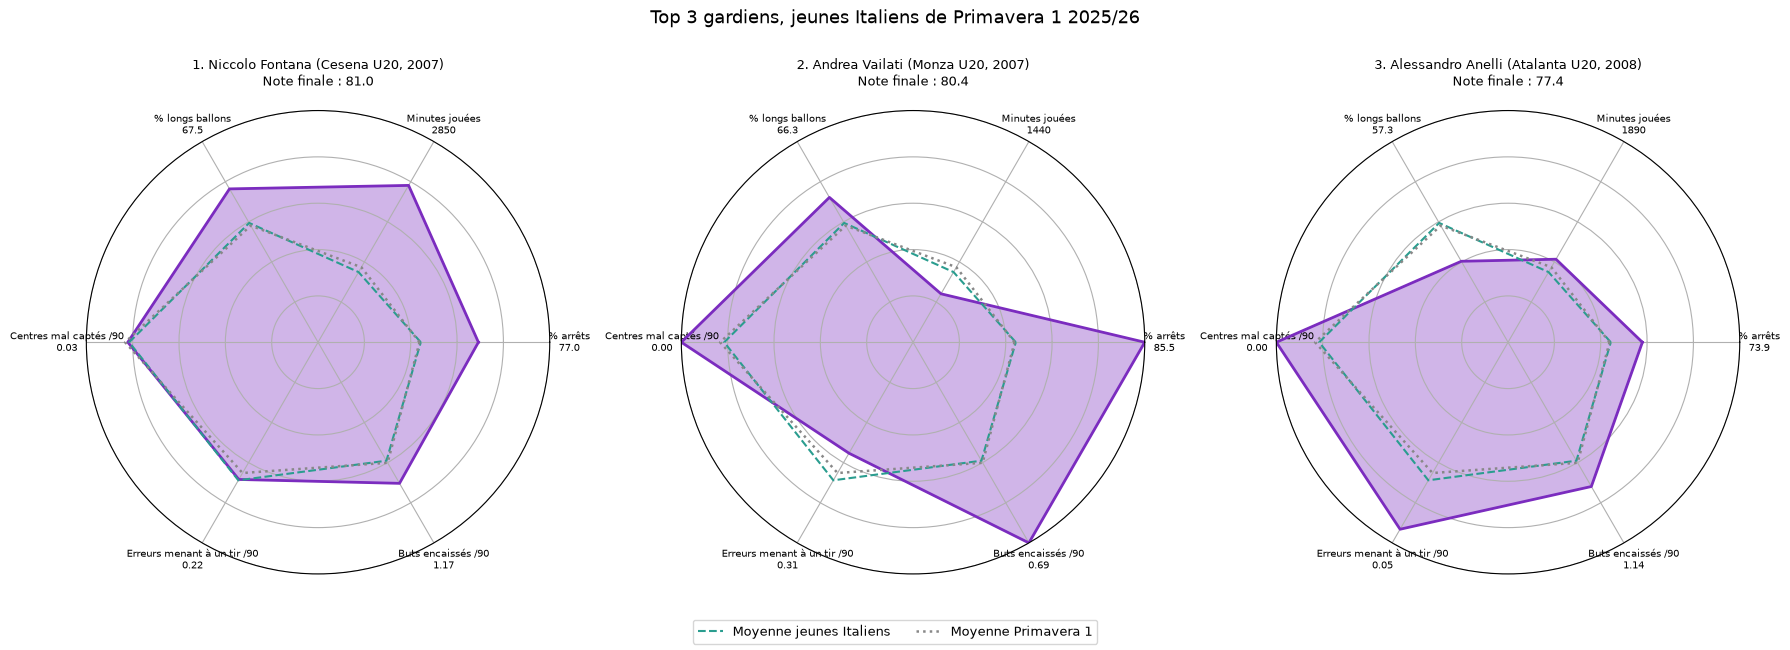

In [7]:
# On affiche les radars du top 3 des gardiens, avec les deux moyennes (l'image est aussi sauvegardée)
afficher_radars(classement_gk, "Gardien")

## 6. Défenseurs

Indicateurs et poids. Défense, 55 % : duels gagnés 14 %, duels aériens gagnés 10 %, ballons récupérés par 90 minutes 9 %, dégagements et tirs contrés par 90 minutes 9 %, fois dribblé par 90 minutes 9 %, erreurs menant à un tir par 90 minutes 4 %. Relance, 30 % : passes réussies 10 %, passes réussies dans le dernier tiers par 90 minutes 10 %, longs ballons réussis 10 %. Temps de jeu, 15 %.

SofaScore ne fournit ni tacles ni interceptions en Primavera. Latéraux et centraux sont classés ensemble : les indicateurs ont été choisis pour équilibrer les deux profils.

In [8]:
# On calcule le classement des défenseurs
classement_def = calculer_classement("Défenseur")
# On affiche combien de jeunes Italiens sont classés à ce poste
print("Défenseurs classés :", len(classement_def))
# On affiche le top 10
afficher_top(classement_def, "Défenseur")

Défenseurs classés : 69


,rang,nom,equipe,annee_naissance,minutesPlayed,note_finale,bonus_age,note_totalDuelsWonPercentage,note_aerialDuelsWonPercentage,note_recup_90,note_degag_contres_90,note_dribble_90,note_erreurs_90,note_accuratePassesPercentage,note_passes_dernier_tiers_90,note_accurateLongBallsPercentage,note_minutesPlayed
0,1,Leonardo Bovio,Inter U20,2008.0,2161,83.3,3.0,91.3,81.2,78.3,87.0,79.7,43.5,94.2,94.2,100.0,44.9
1,2,Edoardo Sadotti,Fiorentina U20,2006.0,3300,78.6,0.0,58.0,60.9,79.7,79.7,89.9,17.4,79.7,98.6,92.8,94.2
2,3,Dario Pelosi,Frosinone U20,2006.0,3240,77.3,0.0,94.2,91.3,97.1,95.7,65.2,10.1,92.8,14.5,72.5,89.1
3,4,Vittorio Gambardella,Napoli U19,2006.0,2857,76.6,0.0,98.6,94.2,89.9,85.5,68.1,23.2,75.4,39.1,71.0,79.7
4,5,Mattia Pellini,Torino U20,2007.0,3060,76.4,0.0,76.8,98.6,94.2,78.3,73.9,7.2,77.5,42.0,87.0,84.8
5,6,Andrea Cogoni,Cagliari U20,2006.0,2661,74.0,0.0,87.7,85.5,81.2,97.1,47.8,1.4,69.6,71.0,82.6,69.6
6,7,Manuel Villa,Monza U20,2008.0,3330,73.9,3.0,97.1,100.0,84.1,88.4,20.3,24.6,56.5,46.4,43.5,95.7
7,8,Tommaso Macchioni,Sassuolo U20,2006.0,2700,72.8,0.0,33.3,71.0,88.4,93.5,100.0,52.2,73.9,59.4,94.2,72.5
8,9,Pietro Parmiggiani,Atalanta U20,2006.0,1956,70.7,0.0,89.9,66.7,100.0,68.1,69.6,26.1,88.4,56.5,84.1,40.6
9,10,Francesco Verde,Juventus U20,2007.0,2610,68.0,0.0,84.1,54.3,72.5,55.1,53.6,39.1,81.2,92.8,55.1,66.7


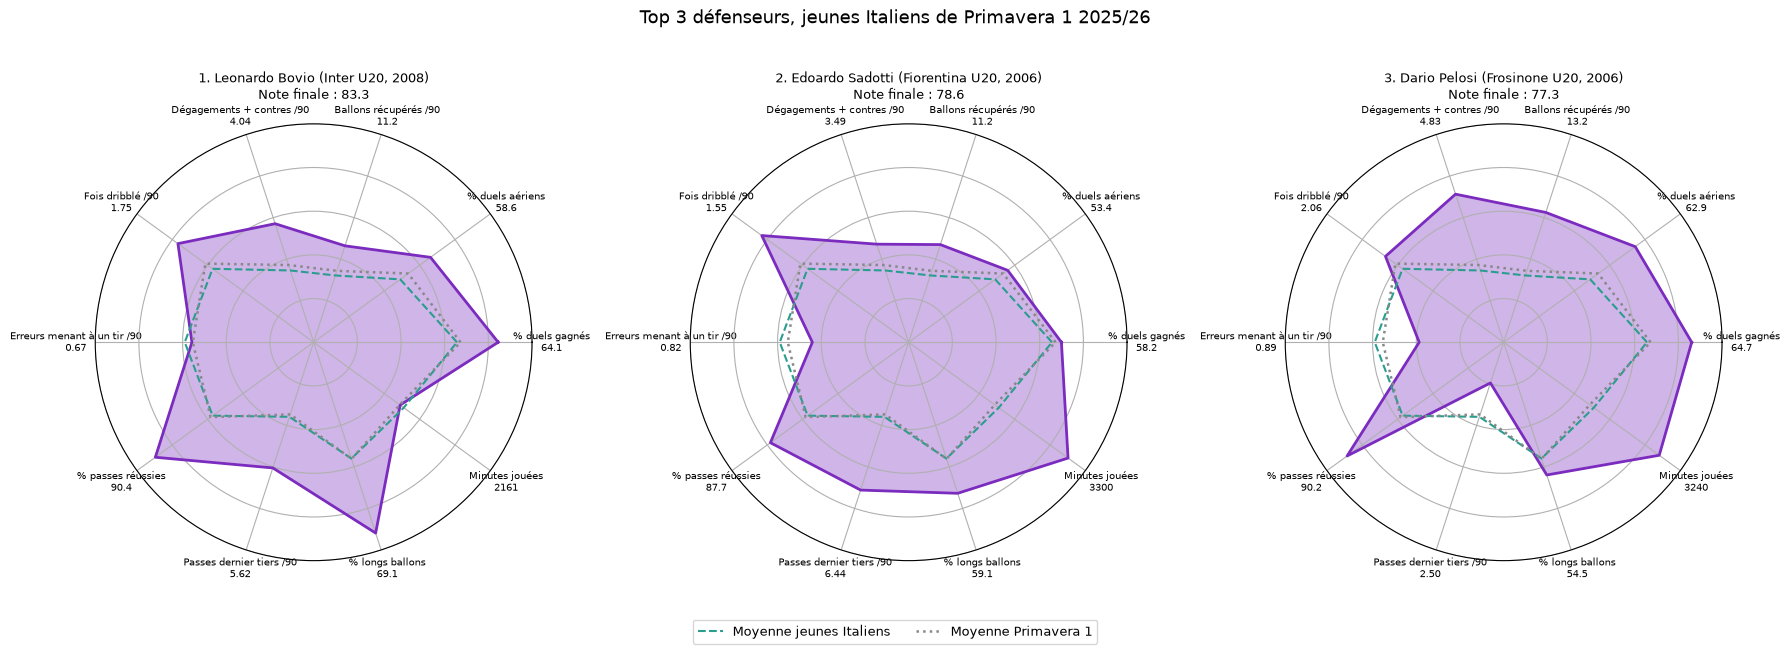

In [9]:
# On affiche les radars du top 3 des défenseurs, avec les deux moyennes (l'image est aussi sauvegardée)
afficher_radars(classement_def, "Défenseur")

## 7. Milieux

Indicateurs et poids. Distribution, 31 % : passes réussies 13 %, passes réussies dans le dernier tiers par 90 minutes 13 %, longs ballons réussis 5 %. Création, 31 % : passes clés par 90 minutes 13 %, buts et passes décisives par 90 minutes 9 %, dribbles réussis par 90 minutes 9 %. Récupération, 23 % : ballons récupérés par 90 minutes 12 %, duels gagnés 11 %. Temps de jeu, 15 %.

In [10]:
# On calcule le classement des milieux
classement_mil = calculer_classement("Milieu")
# On affiche combien de jeunes Italiens sont classés à ce poste
print("Milieux classés :", len(classement_mil))
# On affiche le top 10
afficher_top(classement_mil, "Milieu")

Milieux classés : 117


,rang,nom,equipe,annee_naissance,minutesPlayed,note_finale,bonus_age,note_accuratePassesPercentage,note_passes_dernier_tiers_90,note_accurateLongBallsPercentage,note_passes_cles_90,note_buts_pd_90,note_dribbles_90,note_recup_90,note_totalDuelsWonPercentage,note_minutesPlayed
0,1,Filippo Cerpelletti,Inter U20,2007.0,3086,77.7,0.0,99.1,92.3,74.4,71.8,39.3,12.8,82.1,99.1,95.7
1,2,Marco Buonaiuto,Monza U20,2007.0,1396,75.9,0.0,94.0,76.9,98.3,92.3,54.7,76.1,94.0,77.8,34.2
2,3,Filippo Bertaccini,Cesena U20,2007.0,1769,75.8,0.0,69.2,74.4,51.3,88.0,95.7,53.8,95.7,91.5,54.3
3,4,Filippo Plazzotta,Milan U20,2008.0,1925,74.4,3.0,89.7,94.9,49.1,74.4,71.8,51.3,65.8,63.2,62.4
4,5,Lapo Deli,Fiorentina U20,2006.0,2328,74.2,0.0,91.5,97.4,89.7,78.6,31.6,36.8,87.2,64.1,75.2
5,6,Valerio Farcomeni,Lazio U20,2006.0,1875,73.3,0.0,78.2,77.8,69.2,66.7,66.7,66.7,88.0,88.9,57.3
6,7,Fabio Pandolfi,Milan U20,2008.0,1769,73.1,3.0,81.2,100.0,61.5,59.8,42.7,41.0,97.4,76.1,54.3
7,8,Thomas Poletti,Cesena U20,2008.0,1701,71.5,3.0,68.4,84.6,75.2,82.9,85.9,8.5,81.2,72.6,52.1
8,9,Gabriele Conti,Fiorentina U20,2006.0,1560,71.2,0.0,79.5,94.0,68.4,23.1,100.0,70.1,92.3,84.6,43.6
9,10,Alessandro Di Nunzio,Roma U20,2007.0,2981,69.7,0.0,84.6,79.5,22.2,73.5,67.5,29.1,47.0,85.5,93.2


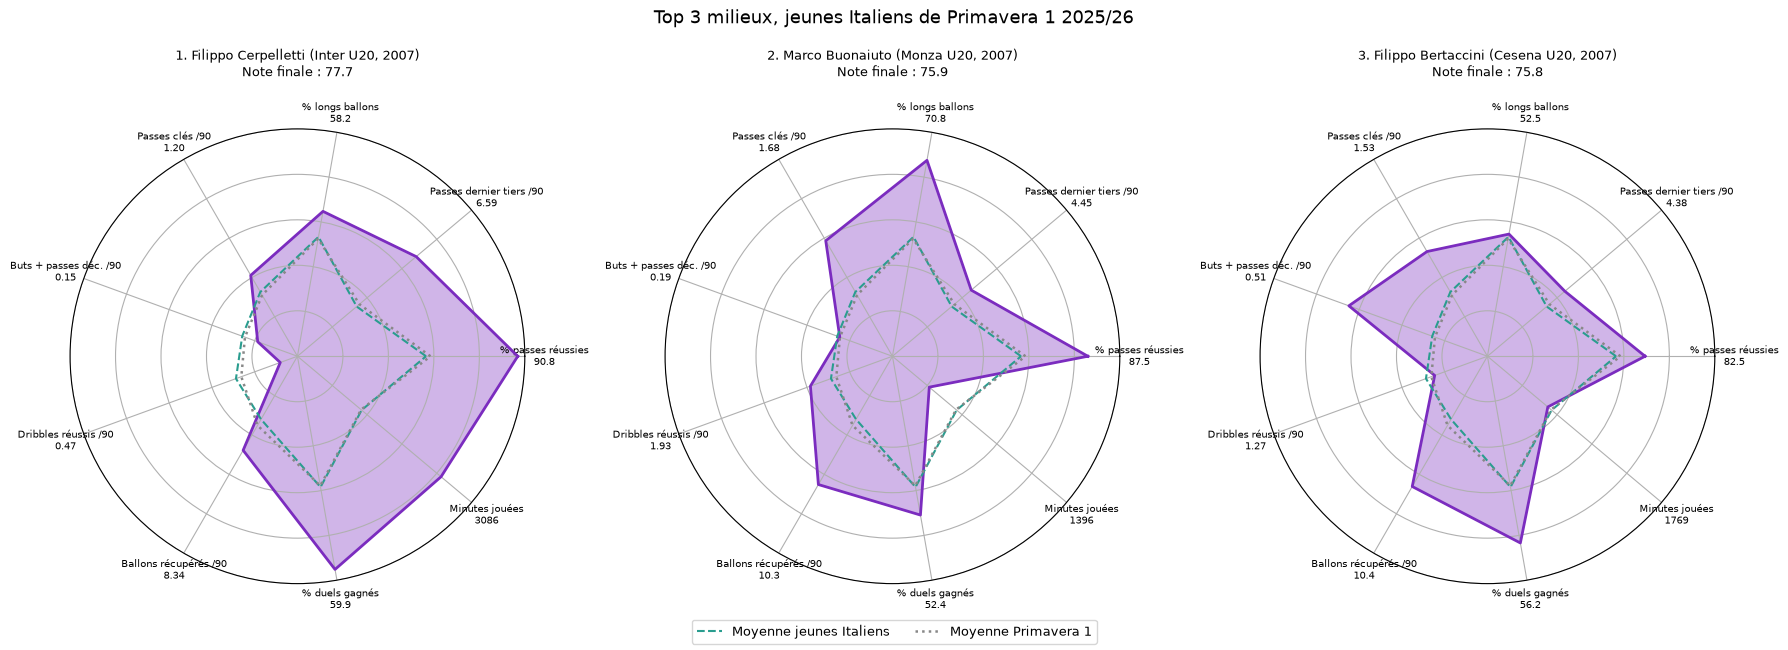

In [11]:
# On affiche les radars du top 3 des milieux, avec les deux moyennes (l'image est aussi sauvegardée)
afficher_radars(classement_mil, "Milieu")

## 8. Attaquants

Indicateurs et poids. Finition, 50 % : buts hors penalty par 90 minutes 25 %, tirs cadrés par 90 minutes 13 %, taux de conversion 12 %. Temps de jeu, 15 %. Création, 15 % : passes décisives par 90 minutes 8 %, passes clés par 90 minutes 7 %. Percussion, 12 % : dribbles réussis par 90 minutes 6 %, pourcentage de dribbles réussis 3 %, fautes subies par 90 minutes 3 %. Combat, 8 % : duels gagnés 4 %, duels aériens gagnés 4 %.

Les penalties sont retirés des buts pour ne pas avantager le tireur désigné de l'équipe.

In [12]:
# On calcule le classement des attaquants
classement_att = calculer_classement("Attaquant")
# On affiche combien de jeunes Italiens sont classés à ce poste
print("Attaquants classés :", len(classement_att))
# On affiche le top 10
afficher_top(classement_att, "Attaquant")

Attaquants classés : 38


,rang,nom,equipe,annee_naissance,minutesPlayed,note_finale,bonus_age,note_buts_hors_pen_90,note_tirs_cadres_90,note_goalConversionPercentage,note_minutesPlayed,note_pd_90,note_passes_cles_90,note_dribbles_90,note_successfulDribblesPercentage,note_fautes_subies_90,note_totalDuelsWonPercentage,note_aerialDuelsWonPercentage
0,1,Simone Lontani,Milan U20,2008.0,1477,83.8,3.0,92.1,100.0,68.4,52.6,89.5,92.1,81.6,36.8,86.8,78.9,81.6
1,2,Nicolò Baldo,Atalanta U20,2006.0,2794,81.9,0.0,89.5,89.5,77.6,94.7,94.7,86.8,65.8,13.2,78.9,52.6,47.4
2,3,Riccardo Braschi,Fiorentina U20,2006.0,2448,77.1,0.0,86.8,94.7,100.0,78.9,92.1,81.6,50.0,21.1,26.3,13.2,28.9
3,4,FIlippo Galvagno,Cesena U20,2007.0,2722,73.2,0.0,97.4,81.6,84.2,92.1,76.3,10.5,23.7,71.1,39.5,10.5,57.9
4,5,Romeo Sandrucci,Torino U20,2007.0,1491,71.1,0.0,84.2,76.3,65.8,55.3,65.8,97.4,78.9,57.9,23.7,89.5,26.3
5,6,Luca Lo Monaco,Bologna U20,2008.0,1476,70.1,3.0,94.7,57.9,63.2,50.0,100.0,100.0,44.7,15.8,10.5,42.1,15.8
6,7,Antonio Arena,Roma U20,2009.0,2218,66.6,5.0,71.1,50.0,92.1,71.1,84.2,34.2,7.9,42.1,55.3,23.7,52.6
7,8,Tommaso Gabellini,Torino U20,2006.0,2660,63.8,0.0,63.2,60.5,81.6,89.5,34.2,65.8,18.4,42.1,68.4,39.5,89.5
8,9,Francesco Castaldo,Bologna U20,2007.0,1529,62.1,0.0,57.9,78.9,26.3,57.9,86.8,63.2,60.5,73.7,63.2,68.4,92.1
9,10,Jamal Iddrissou,Inter U20,2007.0,901,60.9,0.0,81.6,84.2,72.4,13.2,55.3,42.1,36.8,28.9,92.1,57.9,84.2


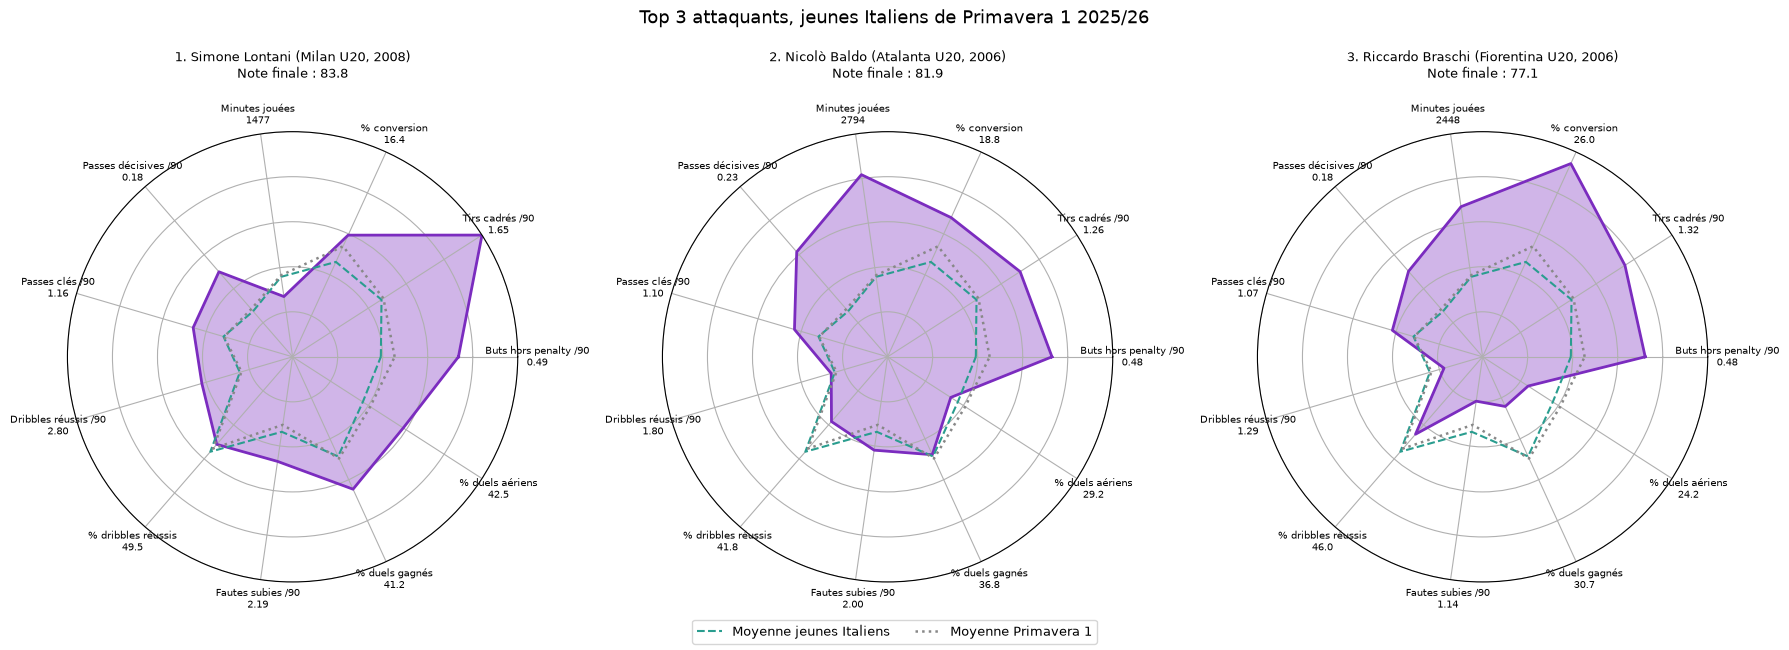

In [13]:
# On affiche les radars du top 3 des attaquants, avec les deux moyennes (l'image est aussi sauvegardée)
afficher_radars(classement_att, "Attaquant")

## 9. XI type des pépites

Le XI est construit en 4.3.3 avec les meilleurs jeunes Italiens de chaque classement : le meilleur gardien, les 4 meilleurs défenseurs, les 3 meilleurs milieux et les 3 meilleurs attaquants. Comme les classements ne distinguent pas latéraux et centraux, ni les différents rôles au milieu et en attaque, ce XI est une sélection par poste large et non une composition tactique.

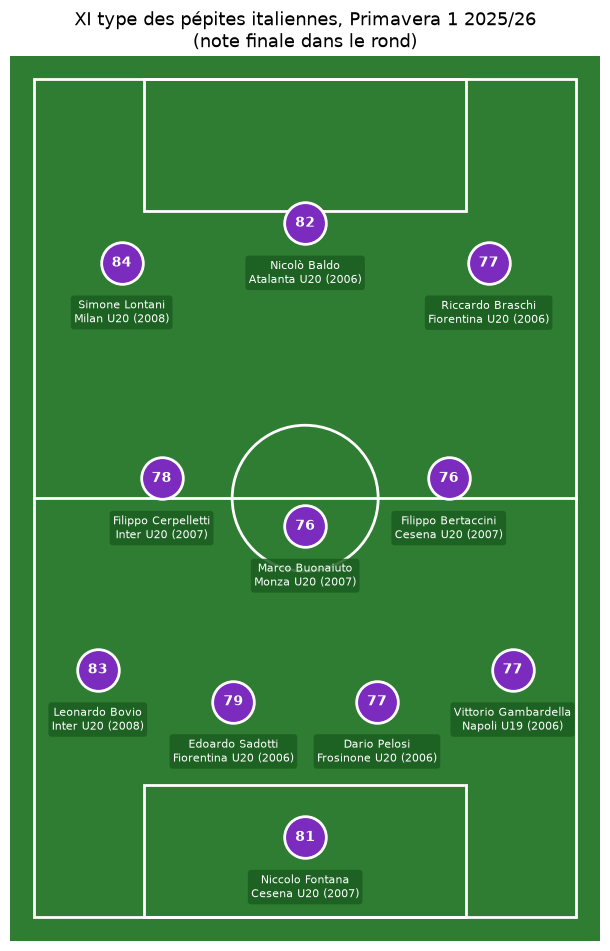

In [14]:
# On importe les formes géométriques de matplotlib (rectangle, cercle) pour dessiner le terrain
from matplotlib.patches import Rectangle, Circle

# On crée la figure du terrain (format vertical)
fig, ax = plt.subplots(figsize=(8, 11.5))
# Le terrain mesure 68 m de large sur 105 m de long, comme un vrai terrain
LARGEUR, LONGUEUR = 68, 105
# On dessine la pelouse verte, un peu plus grande que le terrain (zorder=0 pour qu'elle reste au fond)
ax.add_patch(Rectangle((-3, -3), LARGEUR + 6, LONGUEUR + 6, color="#2E7D32", zorder=0))
# On dessine le contour du terrain
ax.add_patch(Rectangle((0, 0), LARGEUR, LONGUEUR, fill=False, edgecolor="white", linewidth=2, zorder=1))
# On dessine la ligne médiane
ax.plot([0, LARGEUR], [LONGUEUR / 2, LONGUEUR / 2], color="white", linewidth=2, zorder=1)
# On dessine le rond central (rayon de 9,15 m)
ax.add_patch(Circle((LARGEUR / 2, LONGUEUR / 2), 9.15, fill=False, edgecolor="white", linewidth=2, zorder=1))
# On dessine la surface de réparation du bas (40,3 m de large, 16,5 m de profondeur)
ax.add_patch(Rectangle((LARGEUR / 2 - 20.15, 0), 40.3, 16.5, fill=False, edgecolor="white", linewidth=2, zorder=1))
# On dessine la surface de réparation du haut
ax.add_patch(Rectangle((LARGEUR / 2 - 20.15, LONGUEUR - 16.5), 40.3, 16.5, fill=False, edgecolor="white",
                       linewidth=2, zorder=1))

# Positions (x, y) en mètres pour chaque ligne du 4.3.3 : gardien, défense, milieu, attaque
positions = {
    "Gardien": [(34, 10)],
    "Défenseur": [(8, 31), (25, 27), (43, 27), (60, 31)],
    "Milieu": [(16, 55), (34, 49), (52, 55)],
    "Attaquant": [(11, 82), (34, 87), (57, 82)],
}
# Classements correspondant à chaque poste
classements = {"Gardien": classement_gk, "Défenseur": classement_def,
               "Milieu": classement_mil, "Attaquant": classement_att}

# On parcourt chaque poste et ses positions sur le terrain
for poste, places in positions.items():
    # On parcourt chaque place avec son numéro (0 = meilleur du classement)
    for i, (x, y) in enumerate(places):
        # On récupère le joueur classé i au poste
        joueur = classements[poste].iloc[i]
        # On dessine un rond qui représente le joueur
        ax.scatter(x, y, s=900, color="#7B2CBF", edgecolors="white", linewidths=2, zorder=3)
        # On écrit sa note finale dans le rond
        ax.text(x, y, f"{joueur['note_finale']:.0f}", color="white", ha="center", va="center",
                fontsize=10, fontweight="bold", zorder=4)
        # On écrit son nom, son équipe et son année de naissance sous le rond, sur un fond sombre pour rester lisible
        ax.text(x, y - 4.5, f"{joueur['nom']}\n{joueur['equipe']} ({int(joueur['annee_naissance'])})",
                color="white", ha="center", va="top", fontsize=8, zorder=4,
                bbox=dict(facecolor="#1B5E20", edgecolor="none", alpha=0.85, boxstyle="round,pad=0.3"))

# On fixe les limites de l'image autour du terrain
ax.set_xlim(-3, LARGEUR + 3)
# Idem pour la longueur
ax.set_ylim(-3, LONGUEUR + 3)
# On garde les vraies proportions (1 m en largeur = 1 m en longueur), sinon le rond central serait ovale
ax.set_aspect("equal")
# On cache les axes et graduations
ax.axis("off")
# Titre de la figure
ax.set_title("XI type des pépites italiennes, Primavera 1 2025/26\n(note finale dans le rond)", fontsize=13)
# On sauvegarde l'image pour LinkedIn
plt.savefig("xi_type_pepites.png", dpi=200, bbox_inches="tight", facecolor="white")
# On affiche le terrain dans le notebook
plt.show()